<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">Cartography example legend</div>
    </div>
</div>



In [36]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

<Axes: >

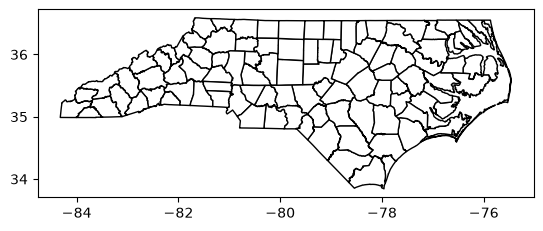

In [37]:


# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


## Code for county level data 

counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].copy()
nc_counties.plot(edgecolor="black", facecolor="white")

<Axes: >

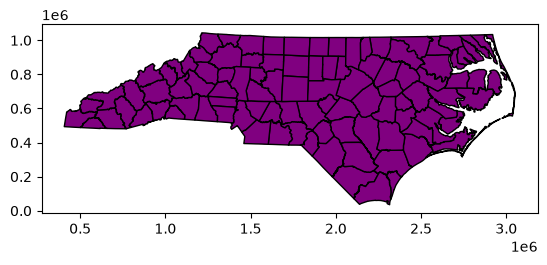

In [38]:
ncc = nc_counties.to_crs(6543).copy()
ncc.plot(edgecolor='black', facecolor='purple')

In [39]:
def ncplot(ax, edge, fill):
    ncc.plot(ax= ax, edgecolor= edge, facecolor = fill)

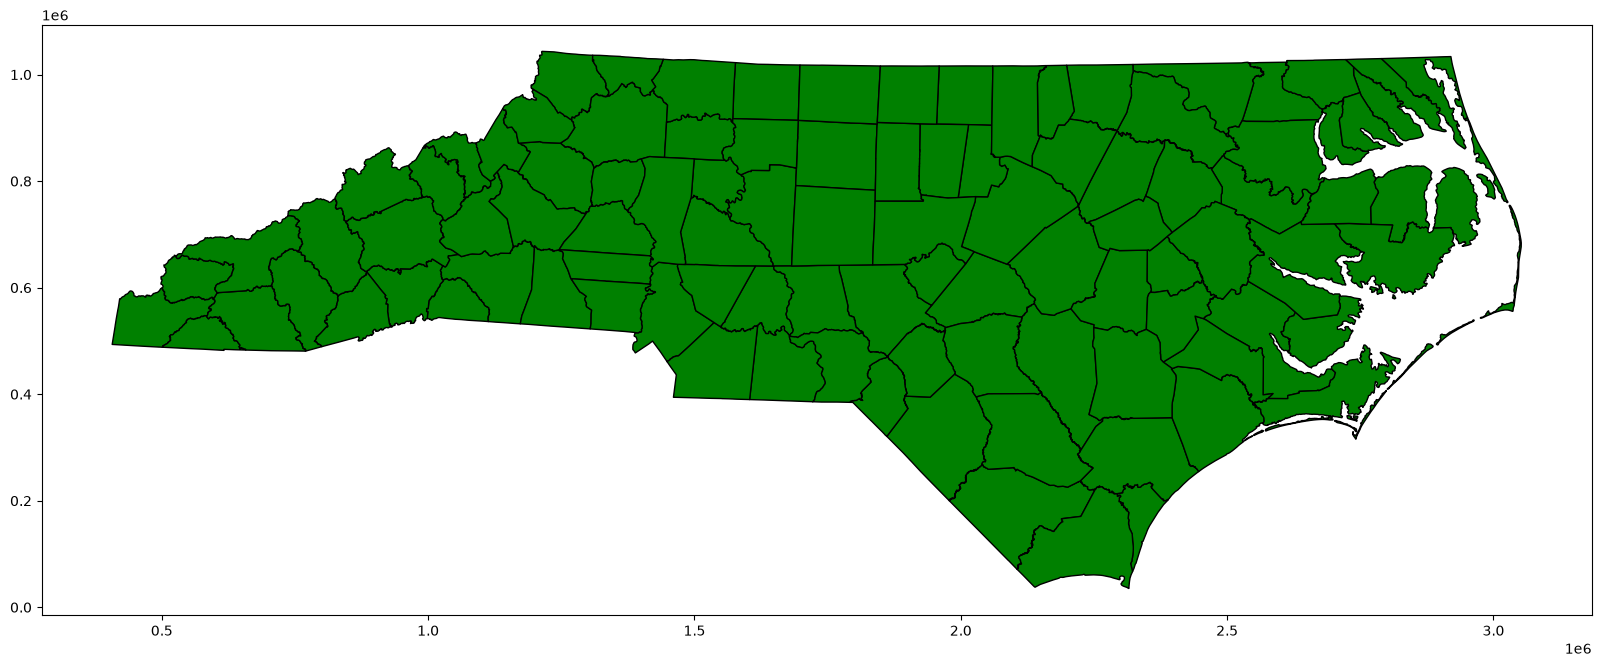

In [40]:
fig, ax = plt.subplots(figsize=(20, 10))
ncplot(ax, 'black', 'green')

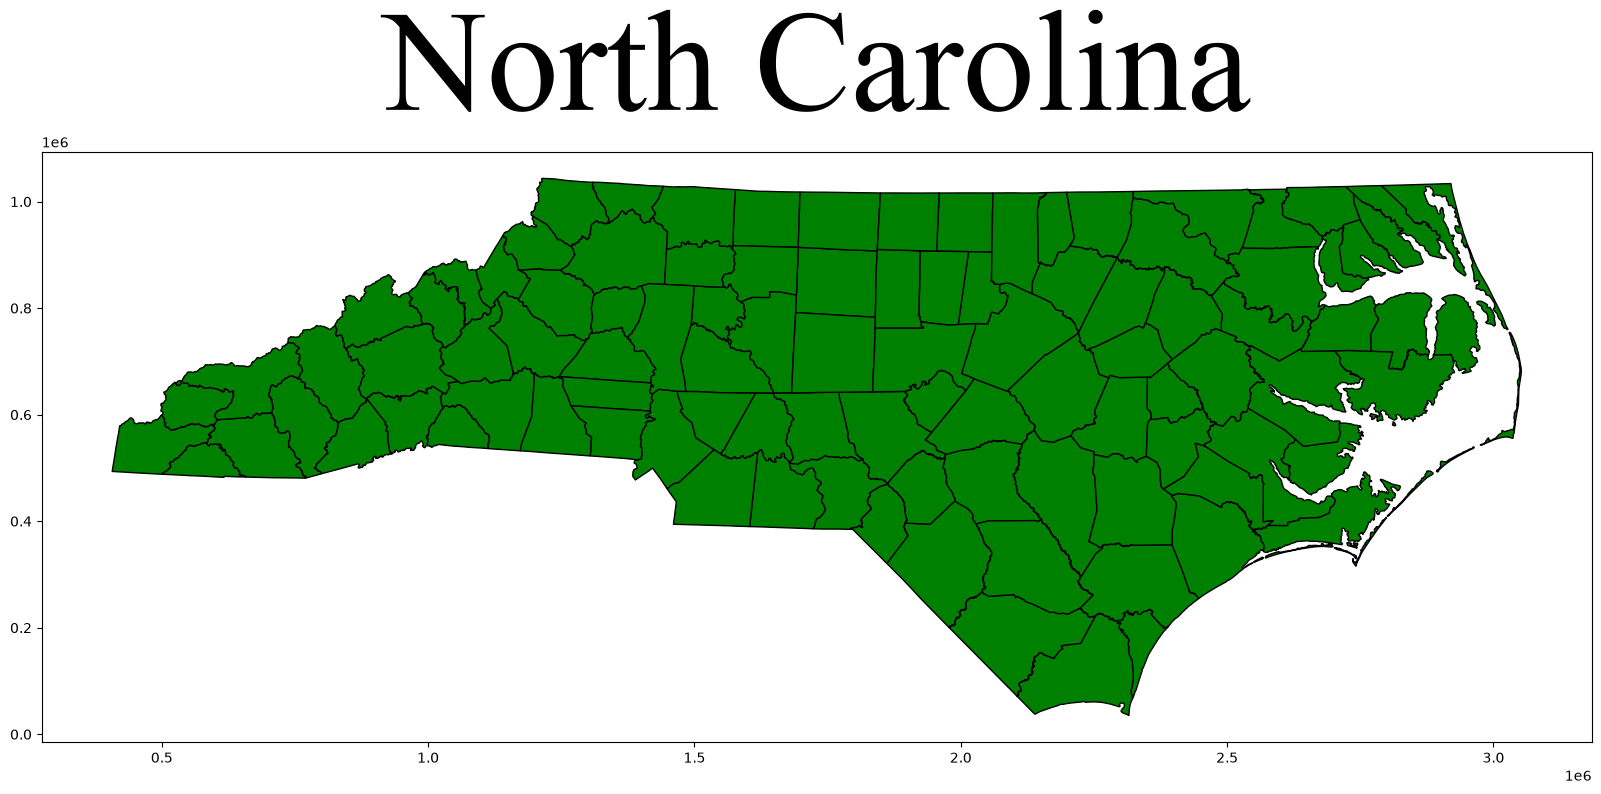

In [41]:
fig, ax = plt.subplots(figsize=(20, 10))
ncplot(ax, 'black', 'green')
ax.set_title('North Carolina', fontsize= 104, pad=30, fontname='Times New Roman')
plt.show()

In [42]:
ncc_copy = ncc.copy()
ncc_copy['geometry'] = ncc_copy.geometry.centroid
ncc_copy['geometry'].head
ncc_copy[ncc_copy['NAME'] == 'Durham']['geometry']

1931    POINT (2036476.502 831990.237)
Name: geometry, dtype: geometry

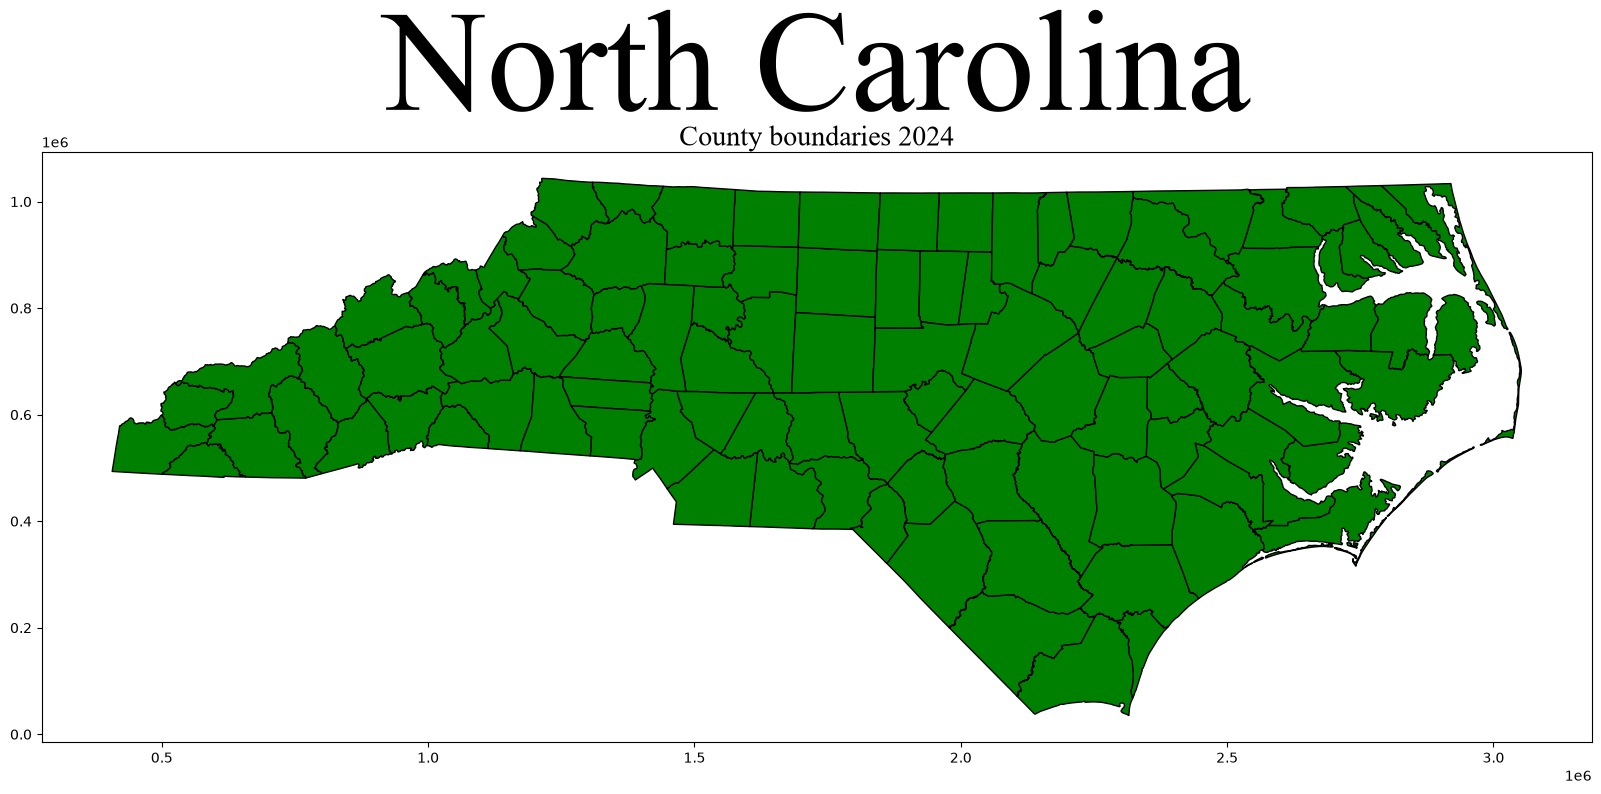

In [43]:
fig, ax = plt.subplots(figsize=(20, 10))
ncplot(ax, 'black', 'green')
ax.set_title('North Carolina', fontsize= 104, pad=30, fontname='Times New Roman')
ax.text(.5, 1.0, 'County boundaries 2024', transform=ax.transAxes, ha='center', va='bottom', fontsize=20, fontname='Times New Roman')
plt.show()

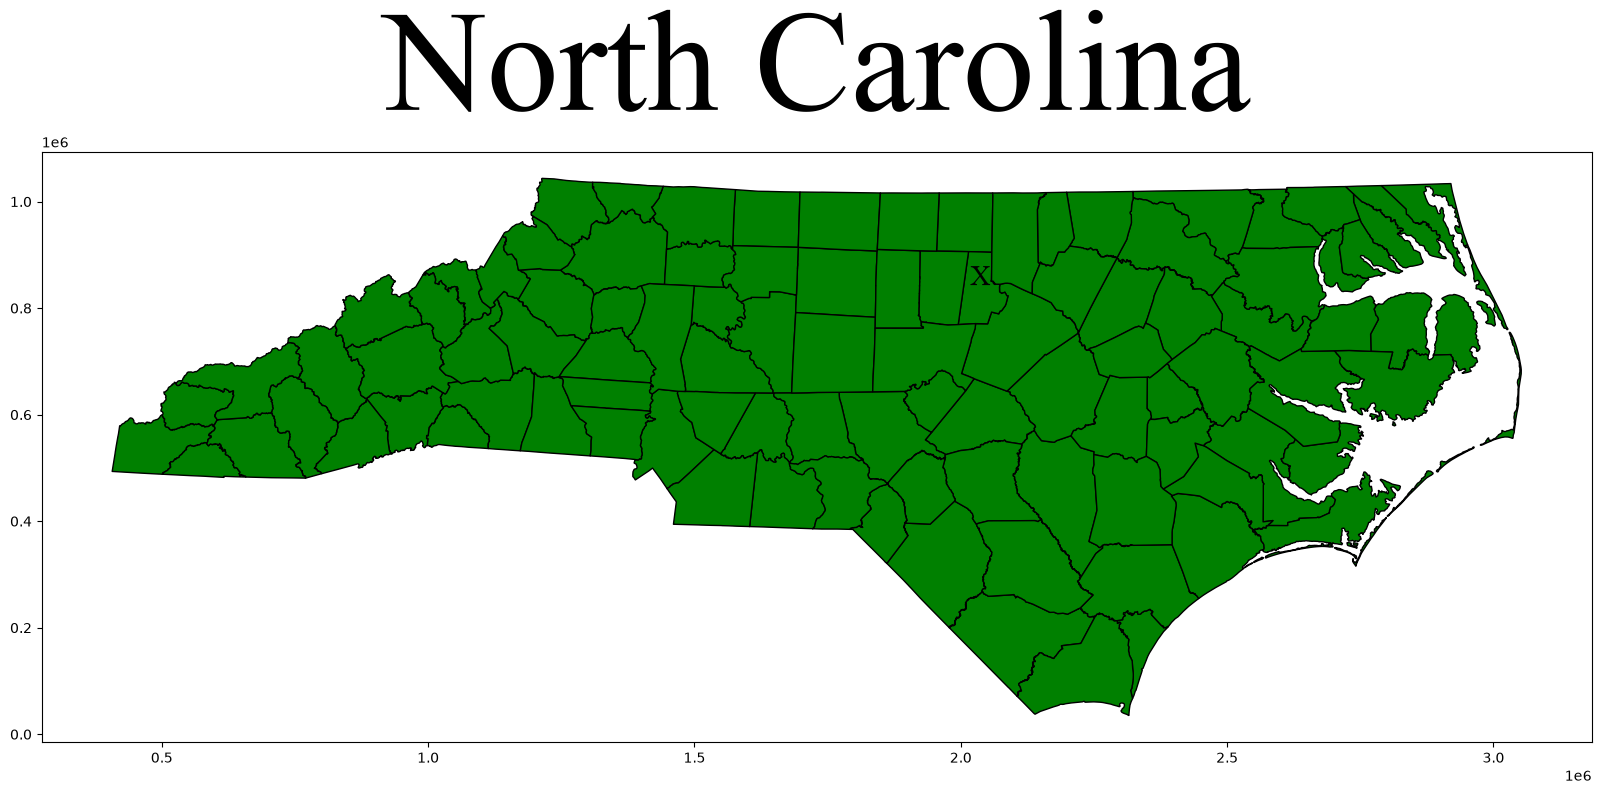

In [44]:
fig, ax = plt.subplots(figsize=(20, 10))
ncplot(ax, 'black', 'green')
ax.set_title('North Carolina', fontsize= 104, pad=30, fontname='Times New Roman')
ax.text(2036476.502, 831990.237, 'X', ha='center', va='bottom', fontsize=20, fontname='Times New Roman')
plt.show()

***Homework***


Plot Xs for all counties like we did for Durham using a loop

In [57]:
for name in ncc_copy['NAME']:
    point = ncc_copy['geometry'][ncc_copy['NAME']==name]

In [69]:
points = gpd.GeoDataFrame(
    ncc_copy['geometry'], geometry=gpd.points_from_xy(ncc_copy.geometry.x, ncc_copy.geometry.y), crs=6543
)

In [103]:
long = []
lat = []
for x in points:
    long.append(points.geometry.x)
    for y in points:
        lat.append(points.geometry.y)

In [100]:
type(points.geometry.x)

pandas.Series

In [104]:
x_val = []
y_val = []
for index, value in long[0].items():
    x_val.append(value)

for index, value in lat[0].items():
    y_val.append(value)

In [111]:
type(x_val)

list

In [109]:
i = 0
for i in x_val:
    x_val[i]
    i += 1

TypeError: list indices must be integers or slices, not float

TypeError: list indices must be integers or slices, not float

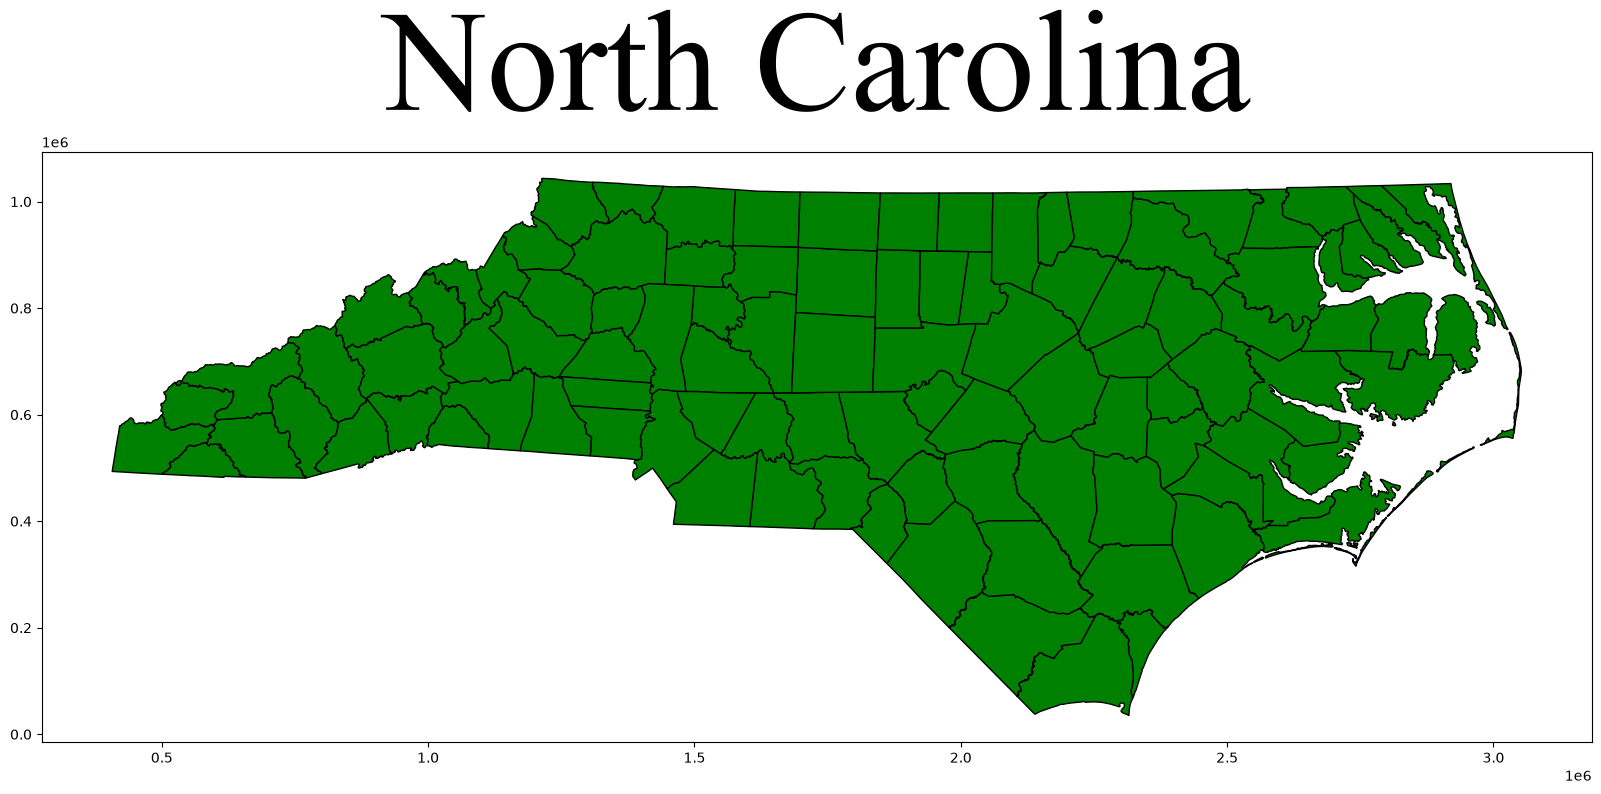

In [108]:
i = 0
fig, ax = plt.subplots(figsize=(20, 10))
ncplot(ax, 'black', 'green')
#points.plot(ax=ax, color='black')
ax.set_title('North Carolina', fontsize= 104, pad=30, fontname='Times New Roman')
for i in x_val:
    ax.text(x_val[i], y_val[i], 'X', ha='center', va='bottom', fontsize=20, fontname='Times New Roman')
    i += 1
plt.show()